# Aqua-Epoch Simple Random Forest Models

**This notebook is the reference for the restored Aqua-Epoch Random Forest architecture.** The supported deployment trainer is `python run.py train`; it fits the same six-feature model inputs and evaluates the website's three-input policy by replacing missing Fluoride, Nitrate, and Conductivity with training-partition medians. Running this notebook's save cell writes all-measurement models directly to the standard joblib paths and can overwrite API artifacts; use the deployment trainer to create website-compatible artifacts.

The notebook's reported hold-out metrics assume all six chemistry values are measured. Website metrics from the supported trainer simulate its median-filled input policy and are recorded in `artifacts/metadata.json`. The pH model has weak predictive signal and its output remains experimental.

## 1. Imports and reproducibility

In [1]:
from __future__ import annotations

import json
from datetime import date
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, classification_report,
    confusion_matrix, f1_score, mean_absolute_error, mean_squared_error,
    precision_score, r2_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline

SPLIT_SEED = 15       # Same hold-out split seed as main2.ipynb
MODEL_SEED = 42       # Same Random Forest seed as main2.ipynb
TEST_SIZE = 0.23      # Same 77/23 train/test split as main2.ipynb

MODEL_FEATURES = [
    'Turbidity', 'Hardness', 'TDS',
    'Fluoride', 'Nitrate', 'Conductivity',
]
CLASSIFICATION_TARGET = 'Potability'
REGRESSION_TARGET = 'pH'

## 2. Load the supplied dataset

The search below works whether Jupyter is started from the project folder or from its `notebooks/` folder.

In [2]:
DATASET_NAME = 'Aqua_Epoch_BIS_Water_Quality_Dataset.csv'

possible_paths = [
    candidate / 'data' / DATASET_NAME
    for root in [Path.cwd(), *Path.cwd().parents]
    for candidate in (root, root / 'aqua_epoch_complete')
]
DATA_PATH = next((path for path in possible_paths if path.is_file()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        f'Could not find {DATASET_NAME}. Expected it in a data/ folder.'
    )

PROJECT_ROOT = DATA_PATH.parent.parent
raw_df = pd.read_csv(DATA_PATH)

print(f'Dataset: {DATA_PATH}')
print(f'Shape before cleaning: {raw_df.shape}')
display(raw_df.head())

Dataset: /Users/shubham_kumar/Desktop/Techfest/aqua_epoch_complete/data/Aqua_Epoch_BIS_Water_Quality_Dataset.csv
Shape before cleaning: (26500, 19)


,pH,Hardness,TDS,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Calcium,Magnesium,Sodium,Potassium,Chloride,Nitrate,Fluoride,Iron,Alkalinity,Potability
0,7.159102,150.155773,16052.651840,5.685047,374.464185,352.121528,11.587073,75.046610,4.966698,61.504002,21.006579,62.345970,2.192344,135.643193,5.561354,1.520887,0.169315,116.950616,0.0
1,6.990053,212.120116,15569.182870,6.872750,319.992702,443.547183,18.268341,123.893737,2.868158,85.238809,28.953441,79.458626,10.197039,168.585701,61.612777,0.786435,0.065204,152.949912,0.0
2,7.110356,204.571035,8183.078691,5.986018,416.595049,311.932109,12.701190,67.312776,4.264031,77.150948,30.591307,62.537654,10.996049,97.220908,9.129196,0.688611,0.124803,153.344413,1.0
3,7.284110,-182.817891,14578.670700,8.454951,372.514273,498.519766,11.753549,58.285792,3.272094,59.718816,26.448595,104.771855,8.332848,165.030904,16.846849,-1.563750,0.180515,173.499347,0.0
4,5.500103,150.299555,25303.762810,7.147440,352.099179,526.743300,15.772748,51.344206,3.407067,58.647298,17.553237,110.628270,12.754797,196.460217,5.390290,1.300669,0.064911,106.874981,0.0


## 3. Basic cleaning from the attached notebook

Invalid physical values are removed. Missing feature values are deliberately left for the model pipeline's median imputer, which avoids fitting preprocessing on the test split.

In [3]:
required_columns = set(MODEL_FEATURES) | {
    CLASSIFICATION_TARGET, REGRESSION_TARGET, 'Potassium'
}
missing_columns = sorted(required_columns - set(raw_df.columns))
if missing_columns:
    raise ValueError(f'Dataset is missing required columns: {missing_columns}')

df = raw_df.copy()
for column in required_columns:
    df[column] = pd.to_numeric(df[column], errors='coerce')

valid_rows = (
    (df[REGRESSION_TARGET].isna() | df[REGRESSION_TARGET].between(0, 14))
    & (df['Hardness'].isna() | (df['Hardness'] >= 0))
    & df['TDS'].between(50, 50_000)
    & (df['Fluoride'].isna() | (df['Fluoride'] >= 0))
    & (df['Nitrate'].isna() | (df['Nitrate'] <= 100))
    & (df['Potassium'].isna() | (df['Potassium'] <= 40))
)
df = df.loc[valid_rows].reset_index(drop=True)

print(f'Rows before cleaning: {len(raw_df):,}')
print(f'Rows after cleaning:  {len(df):,}')
print('Missing values in model inputs:')
display(df[MODEL_FEATURES].isna().sum().to_frame('missing_values'))

Rows before cleaning: 26,500
Rows after cleaning:  21,756
Missing values in model inputs:


,missing_values
Turbidity,47
Hardness,0
TDS,0
Fluoride,1
Nitrate,51
Conductivity,0


## 4. Create classification and regression datasets

In [4]:
X_all = df[MODEL_FEATURES]

classification_rows = df[CLASSIFICATION_TARGET].isin([0, 1])
X_classification = X_all.loc[classification_rows]
y_classification = df.loc[classification_rows, CLASSIFICATION_TARGET].astype(int)

regression_rows = df[REGRESSION_TARGET].notna()
X_regression = X_all.loc[regression_rows]
y_regression = df.loc[regression_rows, REGRESSION_TARGET]

Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X_classification, y_classification,
    test_size=TEST_SIZE, random_state=SPLIT_SEED,
)
Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    X_regression, y_regression,
    test_size=TEST_SIZE, random_state=SPLIT_SEED,
)

print(f'Classification: {len(Xc_train):,} training rows, {len(Xc_test):,} test rows')
print(f'Regression:     {len(Xr_train):,} training rows, {len(Xr_test):,} test rows')
print('Potability distribution:')
display(y_classification.value_counts().sort_index().rename({0: 'Unsafe', 1: 'Safe'}).to_frame('rows'))

Classification: 16,751 training rows, 5,004 test rows
Regression:     16,714 training rows, 4,993 test rows
Potability distribution:


,rows
Potability,
Unsafe,13249
Safe,8506


## 5. Train the simple Random Forest classifier

These parameters match the Random Forest setup in `main2.ipynb`.

In [5]:
classifier = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('model', RandomForestClassifier(
        n_estimators=200,
        max_depth=12,
        min_samples_split=10,
        min_samples_leaf=5,
        max_features=None,
        random_state=MODEL_SEED,
        n_jobs=-1,
    )),
])

classifier.fit(Xc_train, yc_train)
safe_class_index = list(classifier.classes_).index(1)
safe_probabilities = classifier.predict_proba(Xc_test)[:, safe_class_index]
yc_pred = (safe_probabilities >= 0.50).astype(int)

classification_metrics = {
    'accuracy': accuracy_score(yc_test, yc_pred),
    'balanced_accuracy': balanced_accuracy_score(yc_test, yc_pred),
    'precision_safe': precision_score(yc_test, yc_pred, zero_division=0),
    'recall_safe': recall_score(yc_test, yc_pred, zero_division=0),
    'f1_safe': f1_score(yc_test, yc_pred, zero_division=0),
    'roc_auc': roc_auc_score(yc_test, safe_probabilities),
}

pd.Series(classification_metrics, name='classification score').to_frame()

,classification score
accuracy,0.922262
balanced_accuracy,0.935361
precision_safe,0.836838
recall_safe,0.999498
f1_safe,0.910964
roc_auc,0.944240


              precision    recall  f1-score   support

      Unsafe       1.00      0.87      0.93      3013
        Safe       0.84      1.00      0.91      1991

    accuracy                           0.92      5004
   macro avg       0.92      0.94      0.92      5004
weighted avg       0.93      0.92      0.92      5004



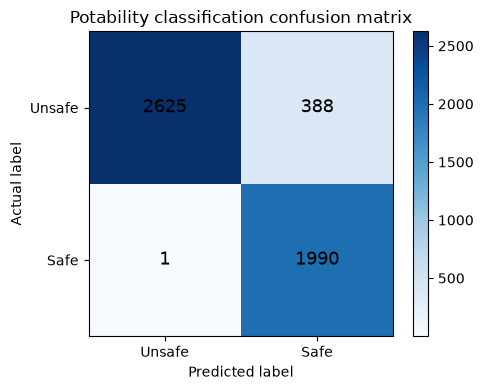

In [6]:
print(classification_report(yc_test, yc_pred, target_names=['Unsafe', 'Safe']))

cm = confusion_matrix(yc_test, yc_pred, labels=[0, 1])
fig, ax = plt.subplots(figsize=(5, 4))
image = ax.imshow(cm, cmap='Blues')
fig.colorbar(image, ax=ax)
ax.set(
    xticks=[0, 1], xticklabels=['Unsafe', 'Safe'],
    yticks=[0, 1], yticklabels=['Unsafe', 'Safe'],
    xlabel='Predicted label', ylabel='Actual label',
    title='Potability classification confusion matrix',
)
for row in range(2):
    for col in range(2):
        ax.text(col, row, cm[row, col], ha='center', va='center', fontsize=13)
plt.tight_layout()
plt.show()

## 6. Train the simple Random Forest pH regressor

The attached notebook identifies pH regression as Model B but does not include its implementation. This uses the same simple Random Forest settings and the same six inputs so that both model tasks remain available.

In [7]:
regressor = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('model', RandomForestRegressor(
        n_estimators=200,
        max_depth=12,
        min_samples_split=10,
        min_samples_leaf=5,
        max_features=1.0,
        random_state=MODEL_SEED,
        n_jobs=-1,
    )),
])

regressor.fit(Xr_train, yr_train)
yr_pred = regressor.predict(Xr_test)

regression_metrics = {
    'mae': mean_absolute_error(yr_test, yr_pred),
    'rmse': float(np.sqrt(mean_squared_error(yr_test, yr_pred))),
    'r2': r2_score(yr_test, yr_pred),
}

pd.Series(regression_metrics, name='regression score').to_frame()

,regression score
mae,0.502621
rmse,0.714311
r2,0.008773


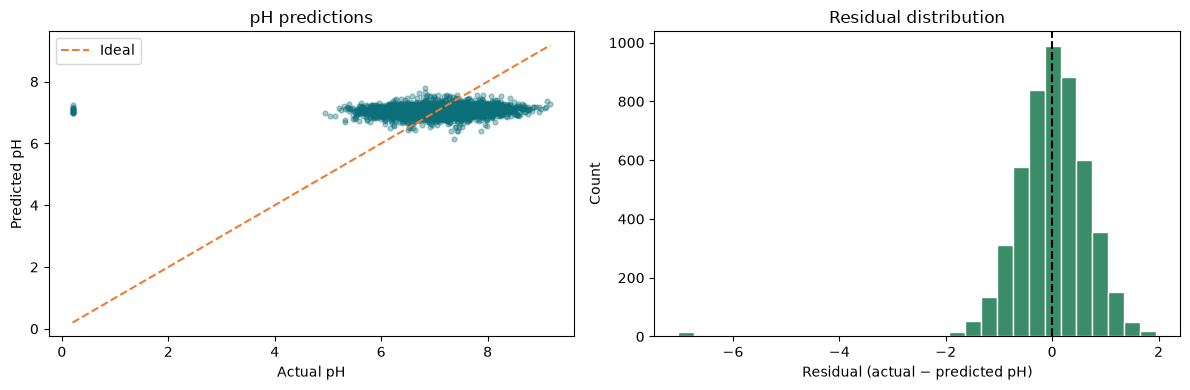

In [8]:
residuals = yr_test.to_numpy() - yr_pred
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

low = min(float(yr_test.min()), float(np.min(yr_pred)))
high = max(float(yr_test.max()), float(np.max(yr_pred)))
axes[0].scatter(yr_test, yr_pred, s=12, alpha=0.35, color='#0a6f78')
axes[0].plot([low, high], [low, high], '--', color='#ee7d32', label='Ideal')
axes[0].set(xlabel='Actual pH', ylabel='Predicted pH', title='pH predictions')
axes[0].legend()

axes[1].hist(residuals, bins=30, color='#3b8c68', edgecolor='white')
axes[1].axvline(0, color='black', linestyle='--')
axes[1].set(xlabel='Residual (actual − predicted pH)', ylabel='Count', title='Residual distribution')

plt.tight_layout()
plt.show()

## 7. Inspect the model feature importance

Feature importance describes the model's split usage. It does not prove a chemical cause-and-effect relationship.

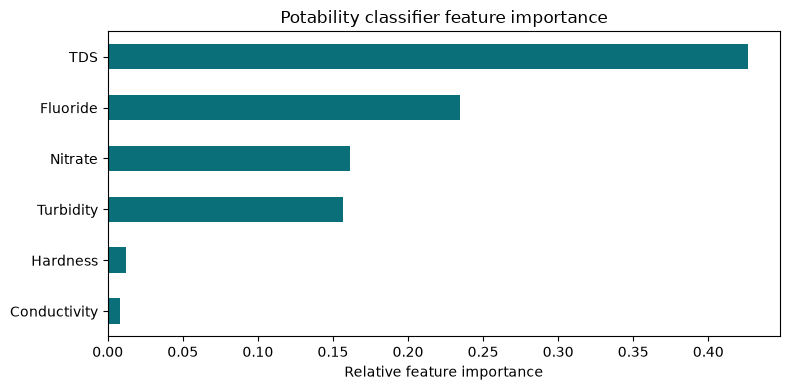

,importance
TDS,0.426421
Fluoride,0.234713
Nitrate,0.161400
Turbidity,0.156922
Hardness,0.012189
Conductivity,0.008354


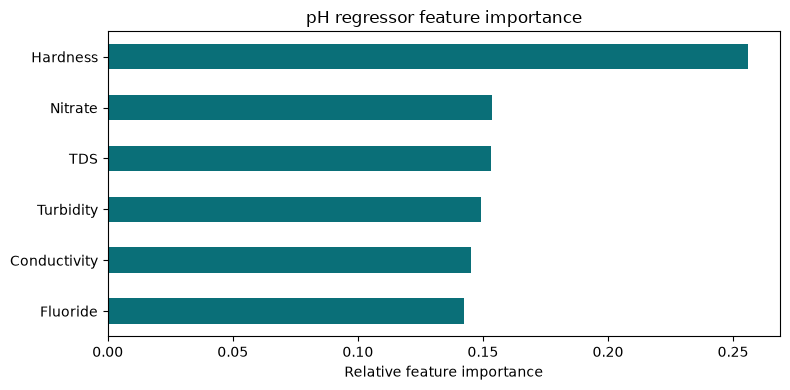

,importance
Hardness,0.255966
Nitrate,0.153680
TDS,0.153213
Turbidity,0.149292
Conductivity,0.145263
Fluoride,0.142586


In [9]:
def plot_feature_importance(model_pipeline, title):
    importance = pd.Series(
        model_pipeline.named_steps['model'].feature_importances_,
        index=MODEL_FEATURES,
    ).sort_values()
    ax = importance.plot.barh(figsize=(8, 4), color='#0a6f78')
    ax.set(xlabel='Relative feature importance', title=title)
    plt.tight_layout()
    plt.show()
    return importance.sort_values(ascending=False).to_frame('importance')

display(plot_feature_importance(classifier, 'Potability classifier feature importance'))
display(plot_feature_importance(regressor, 'pH regressor feature importance'))

## 8. Save the trained models

The two `.joblib` files can be loaded later with `joblib.load(...)`. The JSON file records the model inputs and evaluation values.

In [10]:
MODELS_DIR = PROJECT_ROOT / 'models'
ARTIFACTS_DIR = PROJECT_ROOT / 'artifacts'
MODELS_DIR.mkdir(exist_ok=True)
ARTIFACTS_DIR.mkdir(exist_ok=True)

classifier_path = MODELS_DIR / 'potability_classifier.joblib'
regressor_path = MODELS_DIR / 'ph_regressor.joblib'
metadata_path = ARTIFACTS_DIR / 'simple_model_metadata.json'

joblib.dump(classifier, classifier_path)
joblib.dump(regressor, regressor_path)

metadata = {
    'model_version': 'simple-rf-notebook-1.0',
    'trained_on': str(date.today()),
    'dataset': DATA_PATH.name,
    'model_features': MODEL_FEATURES,
    'classification_model': 'RandomForestClassifier (200 trees, max depth 12)',
    'regression_model': 'RandomForestRegressor (200 trees, max depth 12)',
    'classification_metrics': {key: float(value) for key, value in classification_metrics.items()},
    'regression_metrics': {key: float(value) for key, value in regression_metrics.items()},
}
metadata_path.write_text(json.dumps(metadata, indent=2), encoding='utf-8')

print(f'Classifier saved to: {classifier_path}')
print(f'Regressor saved to:  {regressor_path}')
print(f'Metadata saved to:   {metadata_path}')

Classifier saved to: /Users/shubham_kumar/Desktop/Techfest/aqua_epoch_complete/models/potability_classifier.joblib
Regressor saved to:  /Users/shubham_kumar/Desktop/Techfest/aqua_epoch_complete/models/ph_regressor.joblib
Metadata saved to:   /Users/shubham_kumar/Desktop/Techfest/aqua_epoch_complete/artifacts/simple_model_metadata.json


## 9. Predict one sample

Fill in all six model inputs for a direct prediction.

In [11]:
sample = pd.DataFrame([{
    'Turbidity': 1.0,
    'Hardness': 180.0,
    'TDS': 450.0,
    'Fluoride': float(X_classification['Fluoride'].median()),
    'Nitrate': float(X_classification['Nitrate'].median()),
    'Conductivity': float(X_classification['Conductivity'].median()),
}])[MODEL_FEATURES]

sample_safe_probability = float(classifier.predict_proba(sample)[0, safe_class_index])
sample_ph = float(regressor.predict(sample)[0])

print(f'Potability prediction: {"Safe" if sample_safe_probability >= 0.50 else "Unsafe"}')
print(f'Safe probability:       {sample_safe_probability:.2%}')
print(f'Estimated pH:           {sample_ph:.2f}')
display(sample)

Potability prediction: Unsafe
Safe probability:       41.80%
Estimated pH:           6.67


,Turbidity,Hardness,TDS,Fluoride,Nitrate,Conductivity
0,1.0,180.0,450.0,0.751073,14.307686,423.532578
